In [1]:
%pip install -q numpy matplotlib


In [2]:
csv = """Student,Score
S1,60
S2,65
S3,70
S4,72
S5,68
S6,75
S7,80
S8,77
S9,69
S10,74
"""
with open("exam_scores.csv", "w") as f:
    f.write(csv)
print("Created", "exam_scores.csv")


Created exam_scores.csv


Sample mean              : 71.0
Mean of bootstrap means  : 70.975
95% Confidence Interval  : ( 67.4 , 74.3 )


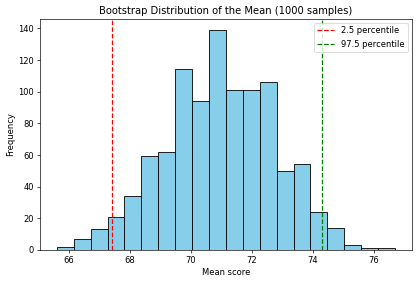

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
scores = np.array([60, 65, 70, 72, 68, 75, 80, 77, 69, 74])

boot_means = []
for _ in range(1000):
    sample = np.random.choice(scores, size=len(scores), replace=True)
    boot_means.append(np.mean(sample))
boot_means = np.array(boot_means)

lower, upper = np.percentile(boot_means, [2.5, 97.5])
print("Sample mean              :", np.mean(scores))
print("Mean of bootstrap means  :", round(boot_means.mean(), 3))
print("95% Confidence Interval  : (", round(lower, 2), ",", round(upper, 2), ")")

plt.figure(figsize=(8, 5))
plt.hist(boot_means, bins=20, color="skyblue", edgecolor="black")
plt.axvline(lower, color="red", linestyle="--", label="2.5 percentile")
plt.axvline(upper, color="green", linestyle="--", label="97.5 percentile")
plt.title("Bootstrap Distribution of the Mean (1000 samples)")
plt.xlabel("Mean score")
plt.ylabel("Frequency")
plt.legend()
plt.show()
